# Análisis Econométrico: Demanda de Costco en México
## Fase 1 - Modelo OLS Final
**Autor:** Hugo Cuellar  
**Fecha:** 24/08/2026  
**Fuente:** INEGI ENIGH 2022  
**Ciudades:** Monterrey (NL), Guadalajara (Jalisco), Querétaro

---

In [2]:
# Especificar y estimar modelo OLS
y = df_model['log_ingreso']
X = df_model[['est_socio_num', 'tam_loc_num', 'es_jalisco', 'es_queretaro']]
X = sm.add_constant(X)

# Comprobar que no existe multicolinealidad perfecta
if np.linalg.matrix_rank(X.to_numpy()) != X.shape[1]:
    raise ValueError('Existe multicolinealidad perfecta en las variables del modelo')

modelo = sm.OLS(y, X).fit()

print('\n' + '=' * 80)
print('ANÁLISIS ECONOMÉTRICO: DEMANDA POTENCIAL DE COSTCO EN MÉXICO')
print('=' * 80)
print(f'\nFecha:                    {datetime.now().strftime("%d/%m/%Y %H:%M")}')
print(f'Observaciones:            {len(df_model):,} hogares')
print('Estados analizados:       Jalisco (14), Nuevo León (19), Querétaro (22)')
print('Categoría base:            Nuevo León (19)')

print('\nINDICADORES DE BONDAD DEL MODELO')
print('-' * 80)
print(f'R-cuadrado (R²):          {modelo.rsquared:.4f} ({modelo.rsquared * 100:.2f}%)')
print(f'R² ajustado:              {modelo.rsquared_adj:.4f}')
print(f'F-statistic:              {modelo.fvalue:.2f}')
print(f'Prob (F-statistic):       {modelo.f_pvalue:.2e}')
print(f'Log-Likelihood:           {modelo.llf:.2f}')
print(f'AIC:                      {modelo.aic:.2f}')
print(f'BIC:                      {modelo.bic:.2f}')

print('\nDISTRIBUCIÓN POR ENTIDAD')
print('-' * 80)
print(df_model['entidad'].value_counts().sort_index())

print('\nTABLA DE COEFICIENTES')
print('-' * 80)
coef_table = pd.DataFrame({
    'Coeficiente': modelo.params,
    'Std Error': modelo.bse,
    't-statistic': modelo.tvalues,
    'P-value': modelo.pvalues,
    'IC 95% Inferior': modelo.conf_int()[0],
    'IC 95% Superior': modelo.conf_int()[1]
})
print(coef_table.to_string())

print('\nRESULTADOS COMPLETOS OLS')
print('-' * 80)
print(modelo.summary())

print('\nINTERPRETACIÓN ECONÓMICA')
print('-' * 80)
print(f'El estrato socioeconómico tiene un coeficiente de {modelo.params["est_socio_num"]:.4f}.')
print(f'Jalisco se compara con Nuevo León mediante un coeficiente de {modelo.params["es_jalisco"]:.4f}.')
print(f'Querétaro se compara con Nuevo León mediante un coeficiente de {modelo.params["es_queretaro"]:.4f}.')
print('Los coeficientes estatales no representan una decisión definitiva de ubicación.')

print('\nLIMITACIONES Y CONCLUSIÓN')
print('-' * 80)
print(f'El modelo explica el {modelo.rsquared * 100:.2f}% de la variación observada.')
print('Faltan variables como PIB regional, competencia, densidad comercial y costos de terreno.')
print('Se requieren las Fases 2 y 3 para una recomendación definitiva.')

# Guardar resumen y datos finales
with open(r'..\resultados\02_modelo_resumen_final.txt', 'w', encoding='utf-8') as archivo:
    archivo.write(modelo.summary().as_text())
df_model.to_csv(
    r'..\data\processed\datos_modelo_final_02.csv',
    index=False
)
print('\nResumen y datos finales guardados correctamente.')


ANÁLISIS ECONOMÉTRICO: DEMANDA POTENCIAL DE COSTCO EN MÉXICO

Fecha:                    24/08/2026 20:00
Observaciones:            10,052 hogares
Estados analizados:       Jalisco (14), Nuevo León (19), Querétaro (22)
Categoría base:            Nuevo León (19)

INDICADORES DE BONDAD DEL MODELO
--------------------------------------------------------------------------------
R-cuadrado (R²):          0.0989 (9.89%)
R² ajustado:              0.0985
F-statistic:              275.67
Prob (F-statistic):       3.19e-225
Log-Likelihood:           -11665.37
AIC:                      23340.73
BIC:                      23376.81

DISTRIBUCIÓN POR ENTIDAD
--------------------------------------------------------------------------------
entidad
14    2624
19    3608
22    3820
Name: count, dtype: int64

TABLA DE COEFICIENTES
--------------------------------------------------------------------------------
               Coeficiente  Std Error  t-statistic       P-value  IC 95% Inferior  IC 95% Superi

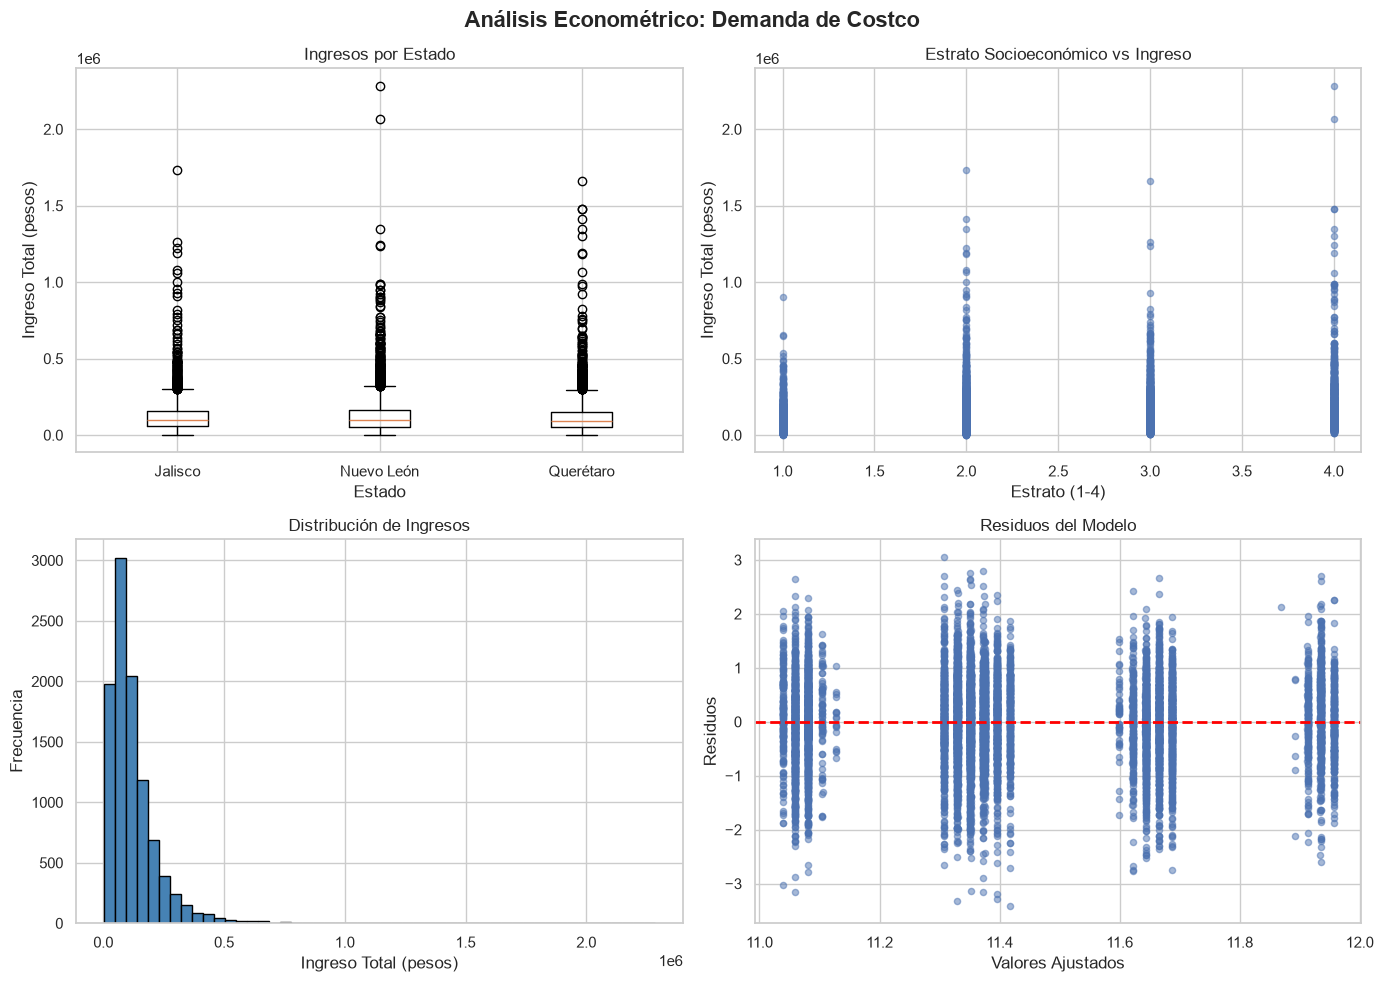

Gráficos guardados en resultados/graficos/02_analisis_visual_final.png


In [3]:
# Crear figura profesional 2x2
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Análisis Econométrico: Demanda de Costco', fontsize=16, fontweight='bold')

# Gráfico 1: Ingresos por estado
datos_estado = [df_model.loc[df_model['entidad'] == estado, 'ingreso_total'] for estado in [14, 19, 22]]
axes[0, 0].boxplot(datos_estado, tick_labels=['Jalisco', 'Nuevo León', 'Querétaro'])
axes[0, 0].set_title('Ingresos por Estado')
axes[0, 0].set_xlabel('Estado')
axes[0, 0].set_ylabel('Ingreso Total (pesos)')

# Gráfico 2: Estrato frente a ingreso
axes[0, 1].scatter(df_model['est_socio_num'], df_model['ingreso_total'], alpha=0.5, s=20)
axes[0, 1].set_title('Estrato Socioeconómico vs Ingreso')
axes[0, 1].set_xlabel('Estrato (1-4)')
axes[0, 1].set_ylabel('Ingreso Total (pesos)')

# Gráfico 3: Distribución de ingresos
axes[1, 0].hist(df_model['ingreso_total'], bins=50, edgecolor='black', color='steelblue')
axes[1, 0].set_title('Distribución de Ingresos')
axes[1, 0].set_xlabel('Ingreso Total (pesos)')
axes[1, 0].set_ylabel('Frecuencia')

# Gráfico 4: Residuos del modelo
axes[1, 1].scatter(modelo.fittedvalues, modelo.resid, alpha=0.5, s=20)
axes[1, 1].axhline(y=0, color='red', linestyle='--', linewidth=2)
axes[1, 1].set_title('Residuos del Modelo')
axes[1, 1].set_xlabel('Valores Ajustados')
axes[1, 1].set_ylabel('Residuos')

plt.tight_layout()
plt.savefig(
    r'..\resultados\graficos\02_analisis_visual_final.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()
print('Gráficos guardados en resultados/graficos/02_analisis_visual_final.png')

In [1]:
import pandas as pd
import numpy as np

# 1. Cargar datos del DENUE
# Descarga los CSVs del DENUE (Sector 46: Comercio al por menor y Sector 72: Alimentos/Bebidas)
# o ajusta la ruta a tu archivo DENUE unificado.
ruta_denue = 'data/raw/denue_comercio.csv'
df_denue = pd.read_csv(ruta_denue, encoding='latin1', low_memory=False)

# 2. Filtrar Zonas de Estudio (Jalisco=14, Nuevo León=19, Querétaro=22)
# 'cve_ent' o los primeros 2 dígitos de 'clee' / 'ubica_geo'
df_denue['entidad_id'] = df_denue['cve_ent'].astype(str).str.zfill(2)
estados_target = ['14', '19', '22']
df_denue = df_denue[df_denue['entidad_id'].isin(estados_target)].copy()

# Crear código de municipio estandarizado (5 dígitos: Entidad + Municipio)
df_denue['ubica_geo'] = (
    df_denue['cve_ent'].astype(str).str.zfill(2) +
    df_denue['cve_mun'].astype(str).str.zfill(3)
)

# 3. Identificar Competencia Directa e Indirecta (Código SCIAN)
# 462111: Comercio al por menor en supermercados
# 462112: Comercio al por menor en mini supers / tiendas de conveniencia
# Filtramos palabras clave para detectar Sam's Club, City Club y Costco existente

nom_comercial = df_denue['nom_estab'].str.upper().fillna('')

# Competidores Directos (Formatos Club)
is_sams = nom_comercial.str.contains("SAM'S|SAMS", regex=True)
is_cityclub = nom_comercial.str.contains('CITY CLUB', regex=False)
is_costco = nom_comercial.str.contains('COSTCO', regex=False)

df_denue['es_competencia_club'] = np.where(is_sams | is_cityclub, 1, 0)
df_denue['costco_existente'] = np.where(is_costco, 1, 0)

# Masa B2B (Restaurantes, Hoteles, Minisúpers -> Compradores de Membresía Business)
# Códigos SCIAN 722 (Servicios de preparación de alimentos y bebidas) y 462112
codigo_scian = df_denue['codigo_scian'].astype(str)
is_b2b = codigo_scian.str.startswith(('722', '462112', '461110'))
df_denue['es_cliente_b2b'] = np.where(is_b2b, 1, 0)

# 4. Agrupar Variables de Oferta por Municipio
oferta_municipal = df_denue.groupby('ubica_geo').agg(
    competidores_club=('es_competencia_club', 'sum'),
    costcos_actuales=('costco_existente', 'sum'),
    densidad_b2b=('es_cliente_b2b', 'sum'),
    total_unidades_economicas=('id', 'count')
).reset_index()

print('Mapeo de oferta completado.')
display(oferta_municipal.sort_values(by='competidores_club', ascending=False).head(10))

FileNotFoundError: [Errno 2] No such file or directory: 'data/raw/denue_comercio.csv'